# MECHA in metafspm, 2: a gradient of soil water potential around a root section

MECHA's legacy puts one soil potential around a section (its scenarios). In the port, the soil's potential is an
input per Compartment (`soil_psi`, role `Soil`): a soil model gives each border wall and junction the potential of
the soil it touches. Here, by hand, a soil drier on one side of the root than on the other, as near a drying
surface, a stone or a neighbouring root's depletion zone, and what it changes in the section:

- where the water enters, and whether some leaves the root on the dry side (hydraulic redistribution);
- the potentials and the pathways across the section;
- how much of this the barriers allow.

The section and the coupling are those of the first tutorial (`tutorial_metafspm_01_granap_mecha.ipynb`); the
problem solved is MECHA's *plant problem*: the soil around each border node, the collar's potential at the xylem.

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.metafspm.coupling.choregrapher import Choregrapher
from openalea.metafspm.coupling.component import StructuralComponent
from openalea.metafspm.data_structure.configs import PropsConfig
from openalea.metafspm.data_structure.data_api import MPGDataStructure
from openalea.metafspm.scene.population import build_population

from openalea.granap.metafspm.component import GranapAnatomy, junction_rules
from openalea.mecha import plots
from openalea.mecha.component import MechaHydraulics

Choregrapher().add_simulation_time_step(3600.)
RADIUS, LENGTH = 0.55e-3, 2e-4                          # m


class OneSegmentRoot(StructuralComponent):
    @classmethod
    def initiate_plant(cls, g, plant, parameters):
        s, L = g.scales, g.labels
        complex_ = plant
        for scale, label in ((s.Axis, L.Axis.Root), (s.GrowthUnit, L.GrowthUnit.Root), (s.Phytomer, L.Phytomer.Root),
                             (s.Organ, L.Organ.RootInternode)):
            complex_ = g.add_component(complex_, **PropsConfig(scale=scale, edge_type='/', label=label))
        segment = g.add_component(complex_, **PropsConfig(scale=s.SubOrgan, edge_type='/',
                                                          label=L.SubOrgan.RootSegment))
        g.property("radius")[segment], g.property("length")[segment] = RADIUS, LENGTH
        g.property("distance_from_tip")[segment] = 0.


plants = pd.DataFrame([dict(plant="p0", model=None, x=0., y=0., z=0., rotation=0., scenario={"parameters": {}})])
g, _ = build_population(plants, initiators=(OneSegmentRoot, GranapAnatomy))
g.convert_properties_to_arraydict()
ds = MPGDataStructure(g, from_scale=g.scales.SubOrgan, nodes="Compartment", wiring=junction_rules(g))
GranapAnatomy(data_structure=ds)()
segment = int(ds.entity_ids("SubOrgan")[0])

ds.register("barrier", np.full(ds.n_nodes(), 3.), location="node")    # a suberized endodermis
mecha = MechaHydraulics(data_structure=ds)
mecha.collar_condition, mecha.collar_psi = 1., -5000.                 # the xylem at -0.5 MPa
mecha.standard_solve = 0.                                             # the plant problem only
COLLAR = mecha.collar_psi

## 1. Where the soil meets the section

MECHA computes, per Compartment, the conductance to the soil (`soil_conductance`): positive on the epidermis' outer
walls and junctions only. These are the nodes a soil model's potential reaches; the others ignore `soil_psi`.
Their angle around the section's centre gives the gradient its direction.

In [2]:
mecha()                                                               # once, for the soil conductances
border = np.asarray(ds.get("soil_conductance")) > 0
x, y = np.asarray(ds.get("section_x")), np.asarray(ds.get("section_y"))           # mm
centre = (x[border].mean(), y[border].mean())
angle = np.arctan2(y - centre[1], x - centre[0])                                  # rad, 0 towards +x
print(f"{int(border.sum())} border walls and junctions in contact with the soil, of {ds.n_nodes()} Compartments")

336 border walls and junctions in contact with the soil, of 8269 Compartments


## 2. A soil wet on one side, dry on the other

The soil potential varies as a cosine of the angle, from `wet` at θ = 0 to `dry` at θ = π. The dry side is drier
than the xylem (−5000 hPa): there, the gradient between the soil and the root reverses.

In [3]:
def soil_around(wet, dry):
    """soil_psi per Compartment (hPa): (wet + dry) / 2 + (wet − dry) / 2 cos θ on the border, 0 elsewhere (unused)."""
    values = (wet + dry) / 2. + (wet - dry) / 2. * np.cos(angle)
    return np.where(border, values, 0.)


def solve(soil):
    ds.set("soil_psi", soil)
    mecha()
    uptake = np.asarray(ds.get("root_uptake")).copy()                  # cm3 d-1, per border node (+: into the root)
    frame = plots.port_frame(mecha, segment, psi="psi", flow="flow", libraries=(GranapAnatomy.library,))
    return dict(uptake=uptake, frame=frame, total=uptake.sum(), entering=uptake[uptake > 0].sum(),
                leaving=max(0., -uptake[uptake < 0].sum()))


SECTORS = np.radians(np.arange(-180., 181., 5.))


def by_sector(uptake):
    """The border nodes' uptake summed by 5° sector of the circumference (walls and junctions alternate along it)."""
    sector = np.digitize(angle[border], SECTORS) - 1
    return np.bincount(sector, weights=uptake[border], minlength=SECTORS.size - 1)[:SECTORS.size - 1]


WET, DRY = -100., -8000.
gradient = solve(soil_around(WET, DRY))
uniform = solve(np.where(border, soil_around(WET, DRY)[border].mean(), 0.))       # the same mean, everywhere
pd.DataFrame({name: {"net uptake (cm³ d⁻¹)": r["total"], "entering": r["entering"], "leaving (released)": r["leaving"]}
              for name, r in (("gradient", gradient), ("uniform, same mean", uniform))}).T

,net uptake (cm³ d⁻¹),entering,leaving (released)
gradient,0.000194,0.002520,0.002327
"uniform, same mean",0.000195,0.000195,0.000000


The net uptake is nearly the same: the section is close to linear, and the mean soil potential sets the net flow.
But with the gradient, water enters on the wet side and part of it leaves on the dry side, through the same
section: the root redistributes water from wet to dry soil, which a single soil potential cannot show.

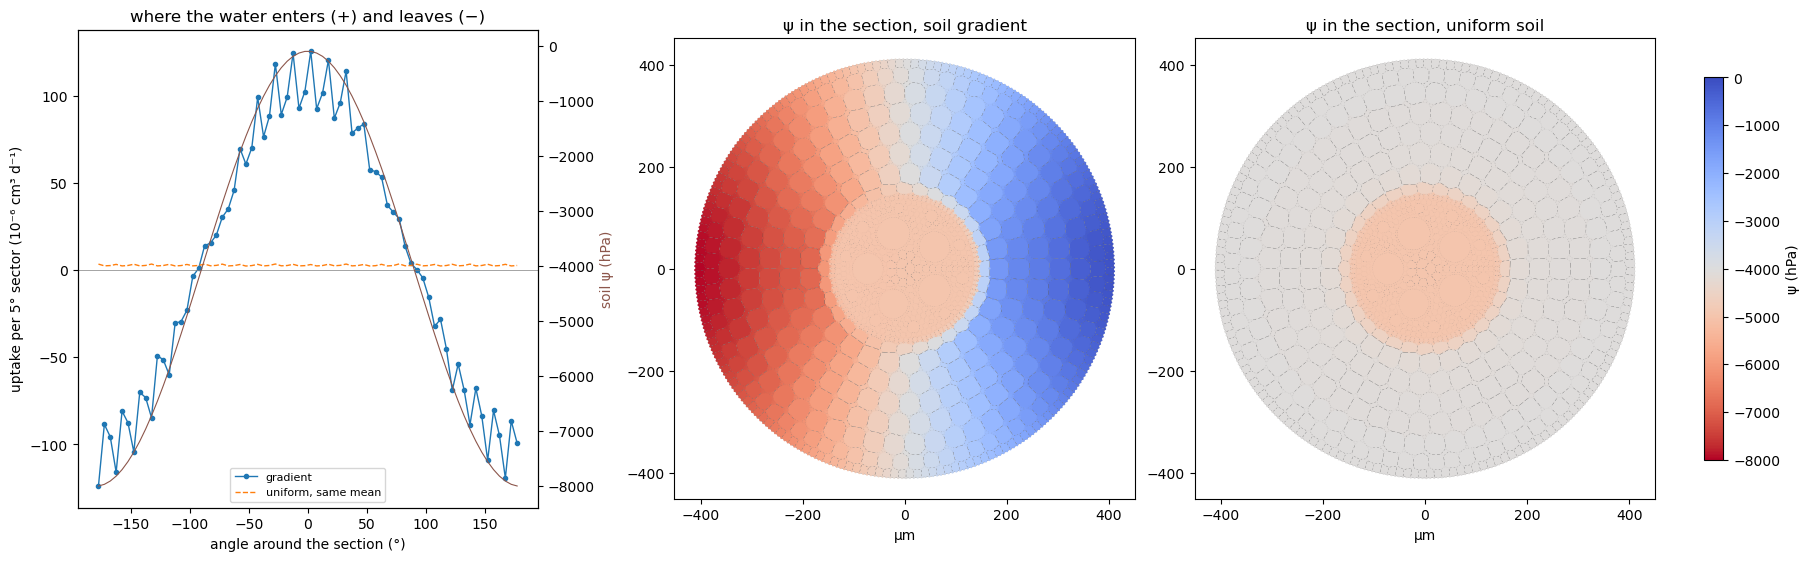

In [4]:
fig = plt.figure(figsize=(18, 5.5), layout="constrained")
ax = fig.add_subplot(1, 3, 1)
middle = np.degrees((SECTORS[:-1] + SECTORS[1:]) / 2)
for result, label, style in ((gradient, "gradient", "o-"), (uniform, "uniform, same mean", "--")):
    ax.plot(middle, by_sector(result["uptake"]) * 1e6, style, ms=3, lw=1, label=label)
ax.axhline(0., color="0.5", lw=0.5)
ax.set(xlabel="angle around the section (°)", ylabel="uptake per 5° sector (10⁻⁶ cm³ d⁻¹)",
       title="where the water enters (+) and leaves (−)")
ax.legend(fontsize=8, loc="lower center")
ax2 = ax.twinx()
ax2.plot(middle, (WET + DRY) / 2. + (WET - DRY) / 2. * np.cos(np.radians(middle)), color="tab:brown", lw=0.8)
ax2.set_ylabel("soil ψ (hPa)", color="tab:brown")

norm = matplotlib.colors.Normalize(DRY, 0.)
ax = fig.add_subplot(1, 3, 2)
points = plots.psi_map(ax, gradient["frame"], title="ψ in the section, soil gradient", norm=norm)
ax = fig.add_subplot(1, 3, 3)
plots.psi_map(ax, uniform["frame"], title="ψ in the section, uniform soil", norm=norm)
fig.colorbar(points, ax=fig.axes[-2:], label="ψ (hPa)", shrink=0.8)
plt.show()

## 3. The flows across the section

The flows as arrows, their length proportional to the flow. The walls (right) carry the water *around* the root,
from the wet side to the dry, in the epidermis' and the cortex's apoplast: with a suberized endodermis (barrier 3)
little of it goes through the stele. The membranes (left) exchange between the cells and their walls, mostly at
the endodermis and around the vessels.

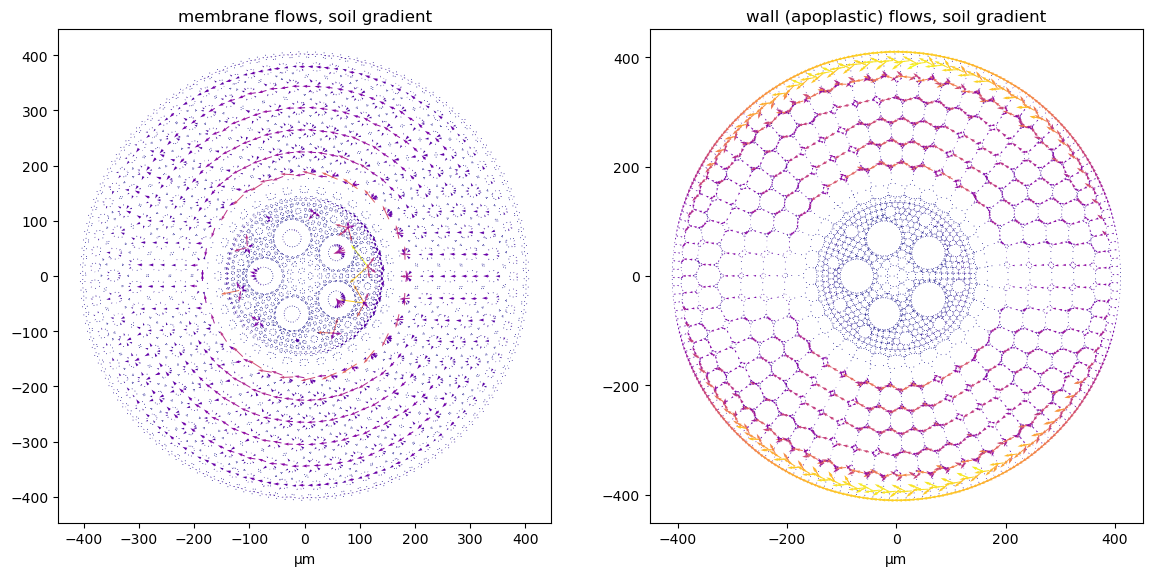

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
q = np.abs(gradient["frame"].Q[(gradient["frame"].path == "membrane") & (gradient["frame"].Q != 0)])
plots.flow_vectors(axes[0], gradient["frame"], path="membrane", title="membrane flows, soil gradient",
                   scale=np.percentile(q, 98) * 60)                  # a few large flows would hide the others
plots.flow_vectors(axes[1], gradient["frame"], path="wall", title="wall (apoplastic) flows, soil gradient")
plt.show()

## 4. How much is redistributed: the gradient's amplitude and the barriers

The share of the water entering the root that leaves it again on the dry side, as the dry side gets drier, for an
endodermal Casparian strip only (barrier 1) and a suberized endodermis (barrier 3). The net uptake reverses where the
soil's mean potential reaches the collar's (the dotted line): beyond, the root loses more than it takes (> 100 %).
The suberized endodermis lowers the net uptake, but redistributes a larger share of what enters: the water that
cannot reach the stele goes around the root to the dry side.

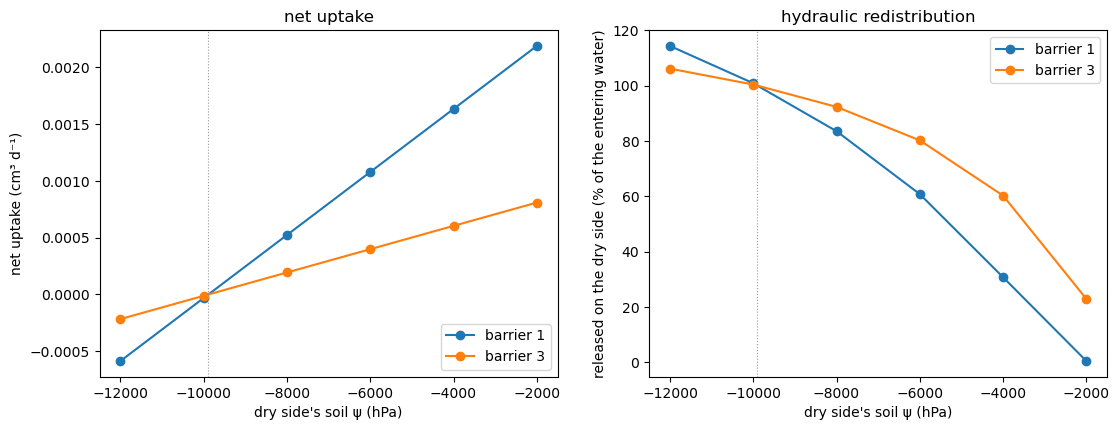

,barrier,dry,net,entering,released
0,1,-2000.0,0.002189,0.002201,0.005486
1,1,-4000.0,0.001634,0.002361,0.307910
2,1,-6000.0,0.001079,0.002753,0.608065
3,1,-8000.0,0.000524,0.003182,0.835365
4,1,-10000.0,-0.000031,0.003629,1.008562
5,1,-12000.0,-0.000586,0.004092,1.143218
6,3,-2000.0,0.000809,0.001051,0.229775
7,3,-4000.0,0.000604,0.001521,0.602772
8,3,-6000.0,0.000399,0.002017,0.802276
9,3,-8000.0,0.000194,0.002520,0.923168


In [6]:
rows = []
for barrier in (1., 3.):
    ds.set("barrier", np.full(ds.n_nodes(), barrier))
    for dry in (-2000., -4000., -6000., -8000., -10000., -12000.):
        r = solve(soil_around(WET, dry))
        rows.append(dict(barrier=int(barrier), dry=dry, net=r["total"], entering=r["entering"],
                         released=r["leaving"] / r["entering"]))
table = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for barrier, rows_b in table.groupby("barrier"):
    axes[0].plot(rows_b["dry"], rows_b["net"], "o-", label=f"barrier {barrier}")
    axes[1].plot(rows_b["dry"], 100 * rows_b["released"], "o-", label=f"barrier {barrier}")
axes[0].set(xlabel="dry side's soil ψ (hPa)", ylabel="net uptake (cm³ d⁻¹)", title="net uptake")
axes[1].set(xlabel="dry side's soil ψ (hPa)", ylabel="released on the dry side (% of the entering water)",
            title="hydraulic redistribution")
for ax in axes:
    ax.axvline(2 * COLLAR - WET, color="0.6", lw=0.8, ls=":")              # the soil's mean at the collar's
    ax.legend()
plt.show()
table.round(6)

## What to take away

- The soil is an input per Compartment: a soil model (metafspm's soil grid, in the fourth tutorial) maps its cells'
  potentials onto each root's border nodes, and MECHA returns `root_uptake` per border node for the soil to take.
- Heterogeneity around a single section, and its consequences (redistribution, the barriers' role), are within
  MECHA's reach without changing it.
- Next: `tutorial_metafspm_03_needle_solutes.ipynb`, an organ of several sections, its transpiration, and solutes.